# 🏦 Predicting Financial Inclusion in Tanzania — Capstone (Worked Example)

**Author:** Data Safari (reference example)  
**Task type:** Binary classification  
**Target:** Whether an adult has a bank account (`has_account`: 1 = yes, 0 = no)

> ⭐ **This is a reference example** showing the standard expected of a capstone. It runs top-to-bottom and demonstrates the full pipeline. **Build your own project on a different Tanzanian problem** — do not submit this one.

---

## 1️⃣ Problem Definition

**Problem:** Across Tanzania, a large share of adults remain **unbanked**. Can we predict, from demographic and behavioural survey features, whether a person has a bank account?

**Why it matters:** Banks, mobile-money providers, and NGOs working on **financial inclusion** can use such a model to **identify and target** likely-unbanked groups with appropriate products and outreach, helping expand access to formal finance.

**Task type & target:** Supervised **binary classification**. Target = `has_account` (1 if the person has any bank account, else 0). The data is **highly imbalanced** (~2.6% positive), so we will judge models by **F1 and recall on the positive class**, not accuracy.

## 2️⃣ Setup & Data Acquisition

*Data source: Tanzania FinScope-style financial-inclusion survey (`FinScope_cleaned1.csv`).*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, roc_auc_score, RocCurveDisplay)

pd.set_option('display.max_columns', None)

In [2]:
# Load the dataset
df = pd.read_csv('FinScope_cleaned1.csv')
print("Shape:", df.shape)
df.head()

,Income_source,Savings_habits,Borrowing_status,Financial_education,Age,Gender,...,has_bank_account
0,employed formal,yes,no,False,42,male,...,no account
1,farmers and fishers,no,yes,False,33,female,...,no account
2,traders nonagricultural,yes,yes,True,51,male,...,two or three accounts
3,farmers and fishers,yes,no,False,29,female,...,no account
4,piece workcasual labor,no,yes,False,60,male,...,no account


## 3️⃣ Data Cleaning & Target Engineering

In [3]:
# Check missing values and types
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Note: these 139 'duplicates' are rows with identical feature values. In survey
# data, different respondents can genuinely share the same answers across these
# columns, so we KEEP them rather than discard real observations. (If the dataset
# had a unique respondent ID, we would instead de-duplicate on that ID.)

Missing values: 0
Duplicate rows: 139

In [4]:
# Engineer a clean binary target from the raw 'has_bank_account' column
df['has_account'] = df['has_bank_account'].map({
    'no account': 0,
    'two or three accounts': 1,
    'more than three accounts': 1
})

print("Target balance:")
print(df['has_account'].value_counts(normalize=True).round(3))

Target balance:
has_account
0    0.974
1    0.026
Name: proportion, dtype: float64

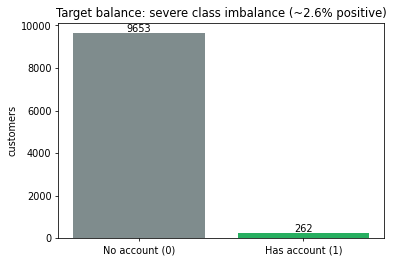

In [5]:
# Visualize the class imbalance
vc = df['has_account'].value_counts().sort_index()
plt.bar(['No account (0)', 'Has account (1)'], vc.values, color=['#7f8c8d', '#27ae60'])
for i, v in enumerate(vc.values):
    plt.text(i, v + 50, str(v), ha='center')
plt.title('Target balance: severe class imbalance (~2.6% positive)')
plt.ylabel('customers')
plt.show()

🔎 Only **2.6%** of people have an account. This is a textbook **imbalanced classification** problem — accuracy would be misleading (predicting "no account" for everyone scores 97.4%). We will use **F1, recall, and ROC-AUC**, and `class_weight='balanced'` in our models.

## 4️⃣ Exploratory Data Analysis

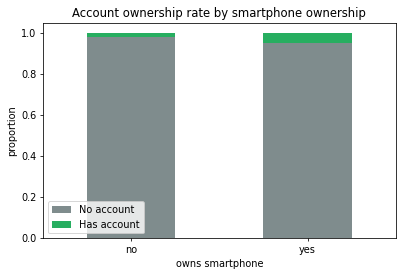

In [6]:
# Does account ownership relate to smartphone ownership?
ct = pd.crosstab(df['Smartphone_ownership'], df['has_account'], normalize='index')
ct.plot(kind='bar', stacked=True, color=['#7f8c8d', '#27ae60'])
plt.title('Account ownership rate by smartphone ownership')
plt.ylabel('proportion'); plt.xlabel('owns smartphone')
plt.legend(['No account', 'Has account'])
plt.xticks(rotation=0)
plt.show()

🔎 **EDA insights**
- People who own a **smartphone** are noticeably more likely to have a bank account — digital access and financial access go together.
- (In a full project you would also explore age, education, income source, and region.) These patterns suggest **technology access, education, and formal employment** will be informative predictors.

## 5️⃣ Feature Engineering & Preparation

We add an `age_group` feature and one-hot encode all categorical variables.

In [7]:
# Feature engineering: bucket age into life-stage groups
df['age_group'] = pd.cut(df['Age'], bins=[17, 30, 45, 60, 100],
                         labels=['youth', 'adult', 'middle', 'senior'])

# Features and target (drop the raw label columns)
X = df.drop(columns=['has_bank_account', 'has_account'])
y = df['has_account']

# One-hot encode categoricals
X = pd.get_dummies(X, drop_first=True, dtype=int)
print("Feature count after encoding:", X.shape[1])

Feature count after encoding: 25

## 6️⃣ Modelling — Baseline (Logistic Regression)

*Split with stratification, then a baseline inside a pipeline (scaling + balanced logistic regression).*

In [8]:
# Stratified split preserves the rare positive class in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

# Baseline pipeline
baseline = Pipeline([
    ('scale', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

print(classification_report(y_test, pred, digits=3))
print("ROC-AUC:", round(roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]), 3))

              precision    recall  f1-score   support

           0      0.989     0.688     0.811      1931
           1      0.058     0.712     0.107        52

    accuracy                          0.688      1983
   macro avg      0.523     0.700     0.459      1983
weighted avg      0.964     0.688     0.793      1983

ROC-AUC: 0.725

🔎 The balanced logistic baseline catches **71% of true account-holders (recall)** at the cost of low precision — a reasonable starting point for a *targeting* use case where missing positives is worse than false alarms. ROC-AUC of **0.725** shows real signal.

## 7️⃣ Improved Model & Tuning — Random Forest + GridSearchCV

In [9]:
# Tune a Random Forest with cross-validation, optimizing F1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

rf_grid = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid={'n_estimators': [100, 200], 'max_depth': [5, 10, None]},
    cv=skf, scoring='f1', n_jobs=-1
)
rf_grid.fit(X_train, y_train)
print("Best params:", rf_grid.best_params_)
print("Best CV F1:", round(rf_grid.best_score_, 3))

best_rf = rf_grid.best_estimator_
pred_rf = best_rf.predict(X_test)
print("Test F1:     ", round(f1_score(y_test, pred_rf), 3))
print("Test ROC-AUC:", round(roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1]), 3))

Best params: {'max_depth': 5, 'n_estimators': 100}
Best CV F1: 0.115
Test F1:     0.134
Test ROC-AUC: 0.726

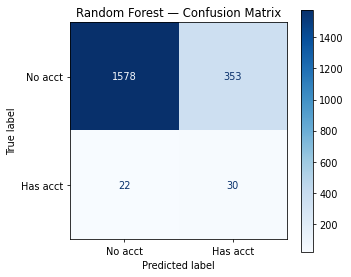

In [10]:
# Confusion matrix for the tuned Random Forest
ConfusionMatrixDisplay.from_estimator(best_rf, X_test, y_test,
                                      display_labels=['No acct', 'Has acct'], cmap='Blues')
plt.title('Random Forest — Confusion Matrix')
plt.show()

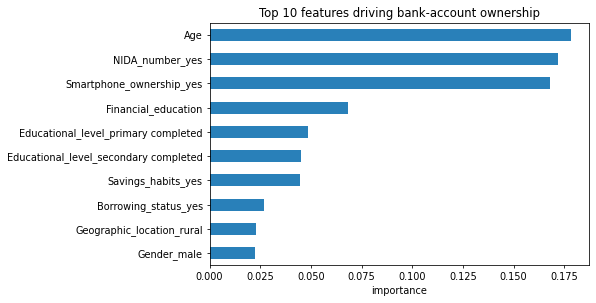

In [11]:
# Which features drive account ownership?
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
importances.head(10).iloc[::-1].plot(kind='barh', color='#2980b9', figsize=(7, 4.5))
plt.title('Top 10 features driving bank-account ownership')
plt.xlabel('importance')
plt.show()

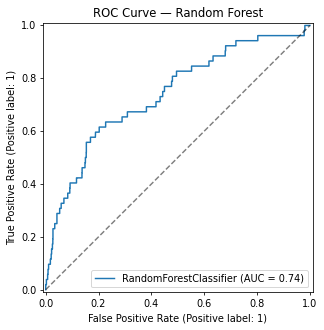

In [12]:
# ROC curve
RocCurveDisplay.from_estimator(best_rf, X_test, y_test)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.5)
plt.title('ROC Curve — Random Forest')
plt.show()

🔎 **Model results**
- The tuned Random Forest improves **F1 from 0.107 → 0.134** over the baseline, with similar ROC-AUC (~0.73).
- **Best params** (`max_depth=5`) — a shallow forest, which makes sense on imbalanced data where deep trees overfit the majority class.
- **Top predictors**: having a **NIDA number** (national ID), **smartphone ownership**, and **age** — i.e. formal identity, digital access, and life stage most strongly signal account ownership.
- This is a **genuinely hard problem** — the modest F1 is honest, not a failure. The model adds real value for *prioritising* outreach even if it cannot perfectly identify every account-holder.

## 8️⃣ Conclusions & Recommendations

**Key findings**
- Bank-account ownership in this survey is **rare (2.6%)** and **hard to predict precisely**, but clear signal exists (ROC-AUC ≈ 0.73).
- The strongest predictors are **formal identity (NIDA), smartphone ownership, age, financial education, and savings habits** — pointing to the roles of digital access and formal documentation in financial inclusion.

**Recommendations**
- Financial-inclusion campaigns should **prioritise adults with digital access and national IDs** as the most reachable near-term segment, while designing **targeted interventions** (e.g. ID-registration support, financial-education drives) for groups the model flags as unlikely.
- Because the goal is *finding* the unbanked-but-reachable, optimise for **recall** and treat the model as a **prioritisation tool**, not a final decision-maker.

**Limitations & next steps**
- Severe class imbalance limits precision; collecting more positive examples or trying resampling (SMOTE) could help.
- Additional features (region, distance to nearest bank/agent, income level) would likely improve the model.
- Validate on a more recent or larger survey before any real deployment.

---
> ✅ This notebook runs top-to-bottom, covers the full pipeline (problem → data → cleaning → EDA → features → modelling → tuning → honest conclusions), and uses **appropriate metrics for imbalanced data**. Use it as a quality bar for your **own** Tanzanian capstone.